In [1]:
# 02 - making fake SA bank statement PDFs (v2) so we can test the pdf parsing
# v2: 9 categories, the printed description is description_sa exactly, amounts in rand
# only needed once if the packages are missing:
# !pip install reportlab pdfplumber
from pathlib import Path
import sys
import pandas as pd

# the code lives in src/ (repo) or next to this notebook (local copy)
sys.path += ["../src", "src", "."]

# find test.csv from notebook 01, same idea as notebook 01 finding the raw csv
PLACES = [Path("../data/processed"), Path("data/processed"), Path("."),
          Path.home() / "finsight_processed", Path.home() / "Downloads" / "finsight_processed"]
PROCESSED = next((p for p in PLACES if (p / "test.csv").exists()), None)
if PROCESSED is None:
    raise FileNotFoundError("test.csv not found - run notebook 01 first, or put test.csv next to this notebook")

# statements go in data/finsight_statements in the repo, otherwise next to test.csv
STMT_DIR = PROCESSED.parent / "finsight_statements" if PROCESSED.name == "processed" else PROCESSED / "finsight_statements"
print("test data :", PROCESSED.resolve())
print("statements:", STMT_DIR.resolve())

test data : /tmp/claude-0/-home-claude/6f9bbf43-f057-5995-bc15-4e1aeee517ad/scratchpad/v2/data/processed
statements: /tmp/claude-0/-home-claude/6f9bbf43-f057-5995-bc15-4e1aeee517ad/scratchpad/v2/data/finsight_statements


In [2]:
# the generator code is in src/pdf_generator.py
# it takes rows from the TEST split only, so the classifier has never seen them
from pdf_generator import generate_statements, BANKS, MONTHLY_COUNTS

print("banks:", [b["name"] for b in BANKS.values()])
print("average spending rows per month:", MONTHLY_COUNTS)

banks: ['Protea Bank', 'Karoo Savings Bank', 'Highveld Mutual']
average spending rows per month: {'Groceries': 9, 'Money Sent': 7, 'Banking': 6, 'Food': 6, 'Transport': 3, 'Shopping': 2, 'Entertainment': 2, 'Other': 1, 'Utilities': 1}


In [3]:
# make 30 statements (10 per bank) + a ground truth csv for each one
# old v1 statements in the folder get deleted first
index, truth = generate_statements(PROCESSED / "test.csv", STMT_DIR)
print(f"{len(index)} statements, {len(truth):,} transactions")
index[["statement_id", "bank_name", "layout", "period_start", "n_transactions", "pdf_file"]].head(6)

30 statements, 1,210 transactions


,statement_id,bank_name,layout,period_start,n_transactions,pdf_file
0,STMT001,Protea Bank,ruled,2023-06-01,43,STMT001_protea.pdf
1,STMT002,Karoo Savings Bank,open,2023-07-01,39,STMT002_karoo.pdf
2,STMT003,Highveld Mutual,zebra,2023-08-01,39,STMT003_highveld.pdf
3,STMT004,Protea Bank,ruled,2023-09-01,34,STMT004_protea.pdf
4,STMT005,Karoo Savings Bank,open,2023-06-01,48,STMT005_karoo.pdf
5,STMT006,Highveld Mutual,zebra,2023-07-01,37,STMT006_highveld.pdf


In [4]:
# what got printed: spending rows use the 9 v2 categories, Income and Transfer are not spending
print(truth.groupby("is_spend")["category"].value_counts().to_string())

is_spend  category     
False     Income            30
          Transfer          18
True      Groceries        276
          Money Sent       233
          Food             183
          Banking          172
          Transport         88
          Shopping          74
          Entertainment     60
          Utilities         41
          Other             35


In [5]:
# ground truth = exactly what is printed on the pdf (used to check the extractor in notebook 03)
truth.sample(8, random_state=1)[["statement_id", "date", "description_sa", "amount", "balance", "category"]]

,statement_id,date,description_sa,amount,balance,category
584,STMT015,2023-08-28,hire's,-74.00,21176.11,Groceries
970,STMT024,2023-09-25,SALARY MOTSWEDI HOLDINGS,27400.00,27846.80,Income
701,STMT018,2023-07-25,SALARY ACACIA LOGISTICS,40100.00,45936.46,Income
619,STMT016,2023-09-18,CHICKEN LICKEN,-19.83,8158.02,Food
534,STMT014,2023-07-21,GAME,-206.09,6908.20,Groceries
126,STMT004,2023-09-05,PURCHASE AUTHORIZED ON 09/01 PlayStation Netwo...,-72.04,4640.12,Shopping
1113,STMT028,2023-09-11,STD BANK INSTANT MONEY Debit PAY ID:CTIvIdzY2c...,-2590.00,3636.70,Money Sent
65,STMT002,2023-07-16,Check Card Withdrawal ENGEN QUICKSHOP / 1137 S...,-38.11,8182.93,Groceries


STMT003_highveld.pdf - 2 pages


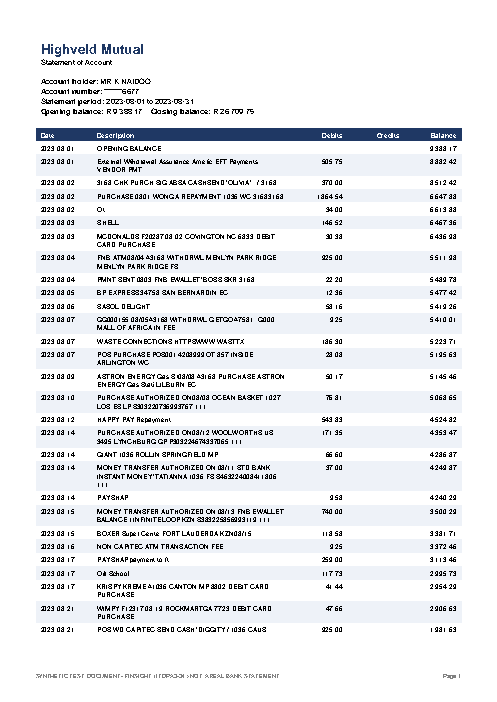

STMT002_karoo.pdf - 2 pages


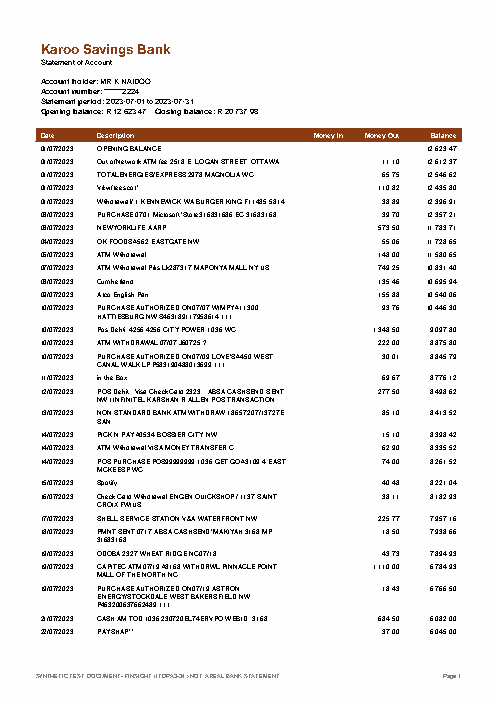

STMT001_protea.pdf - 2 pages


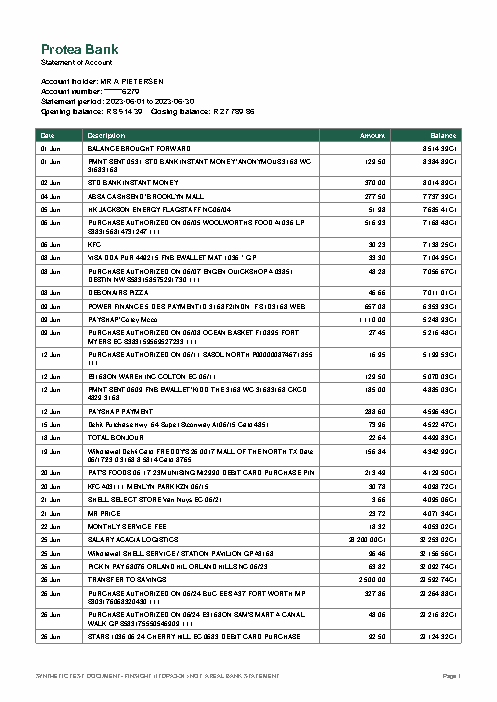

In [6]:
# quick look at page 1 of each bank
import pdfplumber
for f in index.groupby("bank")["pdf_file"].first():
    with pdfplumber.open(STMT_DIR / "pdfs" / f) as pdf:
        print(f, "-", len(pdf.pages), "pages")
        display(pdf.pages[0].to_image(resolution=60))